# 1단계 — 고객 군집화 (analysis_clustering)

목표: 타깃(신용 점수·연체 여부) 없이 6개 입력 변수만으로 고객을 묶어 페르소나를 정의한다.
계산은 `src/analysis_clustering.py`가 하고, 이 노트북은 단계별 결과를 보여 주는 보고서다.

데이터는 A5-1과 같은 `data_gen.py`로 만든 **합성 데이터**이며 실제 금융 고객에 대한 결론이 아니다.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)
# shap이 불러오는 tqdm의 위젯 안내 경고. 출력에 로컬 경로가 남지 않게 숨긴다.
warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

from src import analysis_clustering, clustering
from src.config import FEATURES, FIGURES_DIR, TARGETS
from src.data import features_only, load_data

df = load_data()
X = features_only(df)
print(f"{len(df):,}행, 군집화 입력 {list(X.columns)}")
print("타깃이 입력에 없는가:", set(TARGETS).isdisjoint(X.columns))
X.describe().T[["mean", "std", "min", "max"]]

10,000행, 군집화 입력 ['age', 'annual_income', 'spending_score', 'debt_ratio', 'credit_card_count', 'overdue_count_6m']
타깃이 입력에 없는가: True


,mean,std,min,max
age,44.6204,14.3435,20.0,69.0
annual_income,5033.5813,1934.4579,1500.0,12058.0
spending_score,49.8742,28.7172,1.0,99.0
debt_ratio,0.5013,0.2879,0.0,1.0
credit_card_count,5.0181,2.5715,1.0,9.0
overdue_count_6m,0.5060,0.7157,0.0,4.0


## 1. 왜 스케일링하는가

K-Means는 유클리드 거리로 가까운 고객을 묶는다. 소득(만원, 표준편차 약 2,000)과 부채 비율(0~1)을 그대로 쓰면 거리가 거의 소득만으로 정해진다.
아래는 두 고객 사이 거리에서 각 변수가 차지하는 비중이다.

In [2]:
a, b = X.iloc[0], X.iloc[1]
scaler = clustering.fit_scaler(X)
za, zb = scaler.transform(X.iloc[[0, 1]])
raw_share = (a - b) ** 2 / ((a - b) ** 2).sum()
scaled_share = pd.Series((za - zb) ** 2 / ((za - zb) ** 2).sum(), index=FEATURES)
pd.DataFrame({"customer_0": a, "customer_1": b, "share_raw": raw_share, "share_scaled": scaled_share})

,customer_0,customer_1,share_raw,share_scaled
age,50.00,25.00,4.0248e-04,0.2729
annual_income,3406.00,2161.00,9.9817e-01,0.0372
spending_score,54.00,7.00,1.4225e-03,0.2407
debt_ratio,0.29,0.78,1.5462e-07,0.2602
credit_card_count,1.00,2.00,6.4397e-07,0.0136
overdue_count_6m,1.00,0.00,6.4397e-07,0.1754


## 2. 전체 실행

K 탐색(K=2~8, 시드 5개), K 선택, 최종 군집, 페르소나, PCA, 보너스 알고리즘 비교까지 한 번에 실행하고 `results/clustering.json`에 저장한다.

In [3]:
result = analysis_clustering.run(df)
pd.DataFrame(result["scan"]).set_index("k")

[   0.0s] 데이터 10,000행, 입력 변수 6개 표준화


[  14.2s] K 탐색 완료: Silhouette 최고 K=2, 최종 K=6


[  14.4s] 군집 프로파일·PCA 완료


[  18.0s] 보너스: 알고리즘 비교 완료


[  19.8s] 저장 완료: results\clustering.json


,inertia,silhouette_mean,silhouette_std,silhouette_se,ari_mean
k,,,,,
2,52308.5655,0.1348,0.0045,0.0020,0.6000
3,47181.3505,0.1207,0.0014,0.0006,0.4503
4,43175.8442,0.1274,0.0020,0.0009,0.3473
5,39863.0410,0.1317,0.0016,0.0007,0.3842
6,37316.5849,0.1330,0.0014,0.0006,0.6067
7,35288.0576,0.1312,0.0011,0.0005,0.5266
8,33656.2007,0.1297,0.0024,0.0011,0.5995


## 3. K 선택

규칙: **Silhouette 우선 → Elbow 보조 → 페르소나 해석 가능성** (미션 가이드).

1. Silhouette 평균이 가장 높은 K를 찾고, A5-1과 같은 1-표준오차 규칙으로 차이를 주장하기 어려운 후보를 남긴다.
2. 시드를 바꿔도 군집이 유지되는지(ARI ≥ 0.5) 확인한다.
3. 남은 후보 중 군집을 구별하는 변수가 가장 많은 K를 고른다.

{
 "best_silhouette_k": 2,
 "cutoff": 0.1327296959298778,
 "within_one_se": [
  2,
  6
 ],
 "stable": [
  2,
  6
 ],
 "distinguishing_features": {
  "2": [
   "overdue_count_6m"
  ],
  "6": [
   "age",
   "spending_score",
   "debt_ratio",
   "credit_card_count",
   "overdue_count_6m"
  ]
 },
 "final_k": 6
}


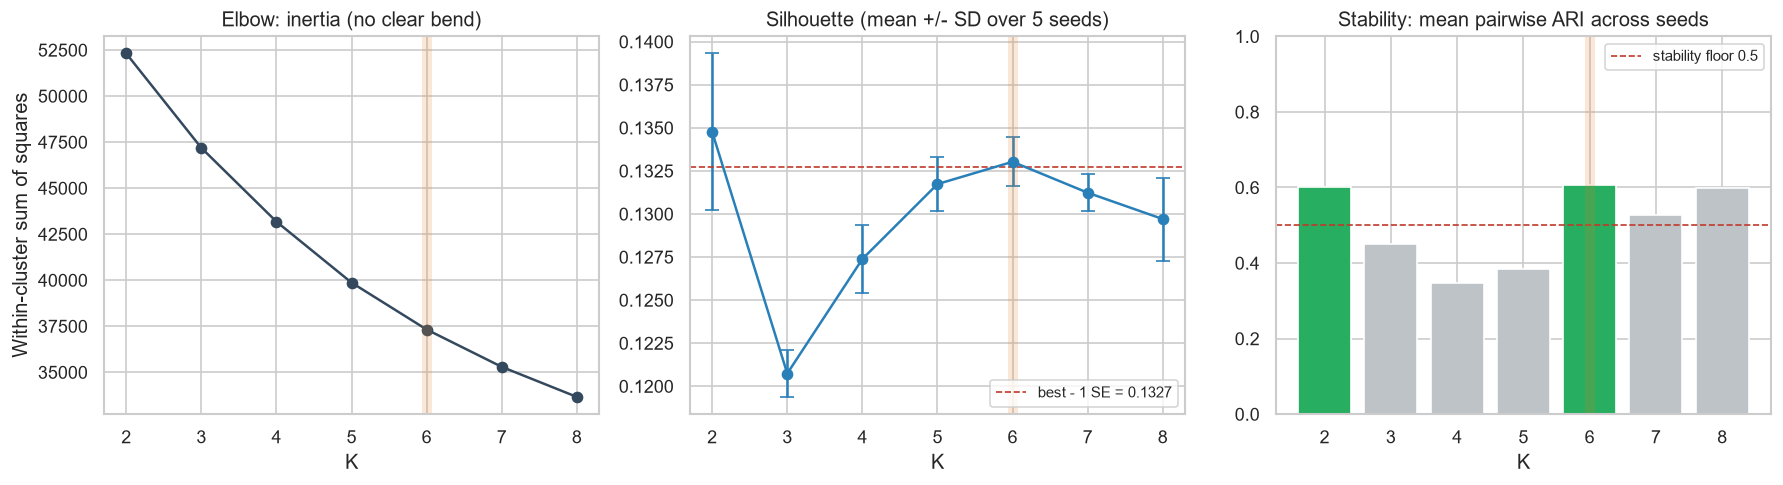

In [4]:
sel = result["selection"]
print(json.dumps(sel, ensure_ascii=False, indent=1))
display(Image(FIGURES_DIR / "01_k_selection.png"))

Silhouette이 모든 K에서 0.12~0.14로 낮고 평평하며, Elbow도 꺾이지 않는다. `data_gen.py`가 6개 변수를 **서로 독립인 난수**로 만들었기 때문이다.
이 데이터에는 자연스러운 군집이 없고, K-Means는 연속적인 공간을 나눌 뿐이다. 그래서 K는 "진짜 군집 수"가 아니라 **운영할 페르소나 수**를 고르는 결정이다.

K=2는 Silhouette이 가장 높지만 "6개월 연체 0회 / 1회 이상" 규칙 하나와 같다. K=6은 통계적으로 K=2와 구별되지 않으면서 5개 변수로 고객을 구별한다.

In [5]:
k2 = clustering.kmeans(2).fit(scaler.transform(X))
pd.crosstab(k2.labels_, df["overdue_count_6m"])

overdue_count_6m,0,1,2,3,4
row_0,,,,,
0,0,2968,813,134,16
1,6069,0,0,0,0


## 4. PCA 2차원 시각화

PCA는 그림을 그리기 위한 투영이다. 군집은 6차원 원래 공간에서 학습했다. 주성분(PC)은 원래 변수가 아니라 변수들의 가중 합이므로, "PC1이 높은 고객" 대신 아래 적재값(loading)으로 해석한다.

설명된 분산: ['17.5%', '17.1%', '16.7%', '16.5%', '16.2%', '16.0%']


,PC1,PC2
age,0.426,-0.501
annual_income,-0.075,0.691
spending_score,0.625,0.035
debt_ratio,-0.558,-0.239
credit_card_count,0.239,0.461
overdue_count_6m,0.232,-0.001


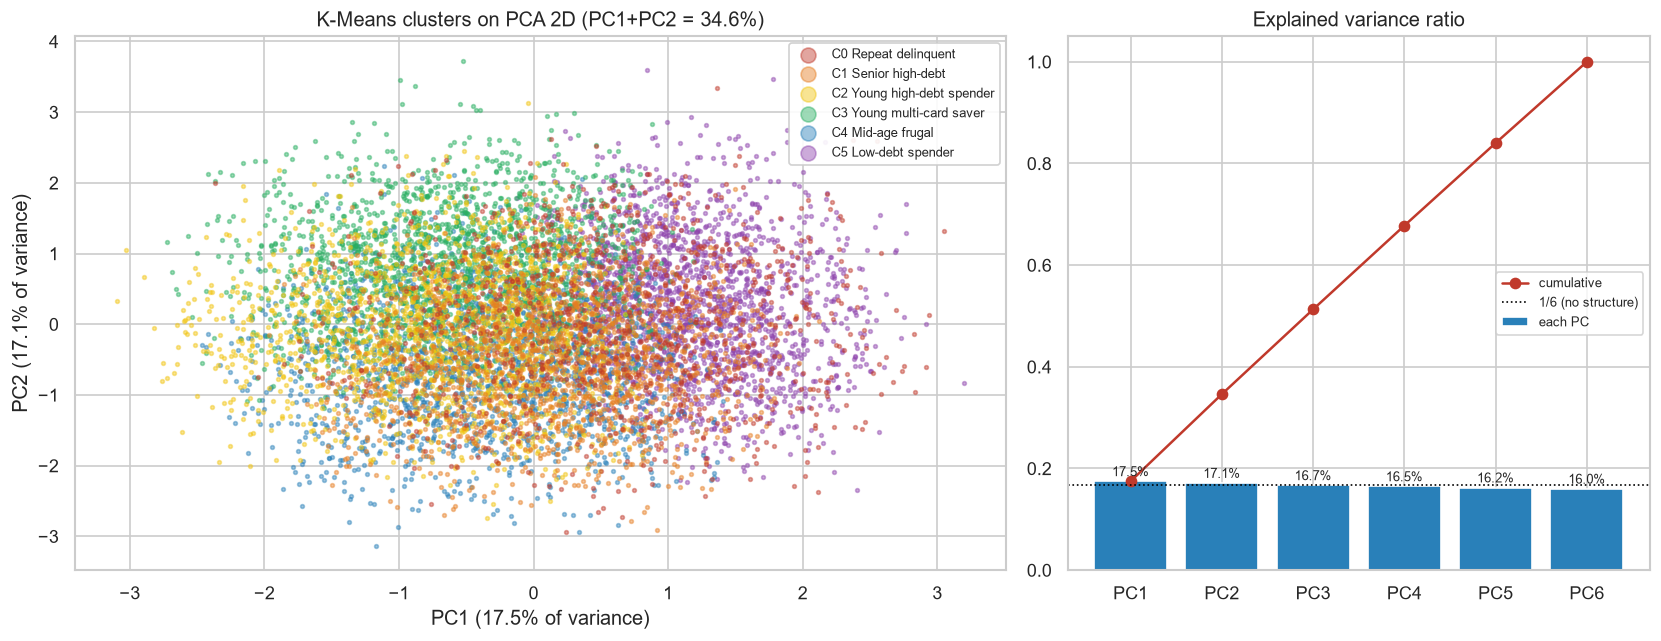

In [6]:
pca = result["pca"]
print("설명된 분산:", [f"{v:.1%}" for v in pca["explained_variance_ratio"]])
display(pd.DataFrame(pca["loadings"]).round(3))
display(Image(FIGURES_DIR / "02_pca_clusters.png"))

변수가 서로 독립이라 주성분마다 설명 분산이 약 1/6(16.7%)이다. PC1+PC2는 34.6%뿐이라 2차원 그림에서 군집이 많이 겹쳐 보인다. 나머지 65%의 차이가 그림에 보이지 않을 뿐, 6차원에서는 군집이 나뉘어 있다.

## 5. 군집 프로파일과 페르소나

연체율과 신용 점수는 군집화에 쓰지 않았다. 군집을 만든 뒤 설명에만 쓴다.

,persona,size,share,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,overdue_rate,credit_score
cluster,,,,,,,,,,,
C0,연체 반복형,962,0.0962,44.8971,5031.3617,50.7422,0.4888,4.9407,2.1726,0.3898,292.7443
C1,고령·고부채 다카드형,1728,0.1728,58.4491,4832.9641,52.0851,0.7223,6.5463,0.3530,0.1574,353.8594
C2,청년·고부채 소비형,1758,0.1758,34.5154,5203.5813,62.6866,0.7307,3.0671,0.3385,0.1320,365.5853
C3,청년·다카드 절약형,1842,0.1842,32.8969,5222.0494,30.1792,0.4919,7.1520,0.3208,0.0765,391.7372
C4,중장년·저소비 실속형,1788,0.1788,50.5196,4816.6051,25.5587,0.3751,2.7975,0.3126,0.0710,389.6795
C5,저부채 고소비 우량형,1922,0.1922,47.0395,5080.7908,77.2284,0.2256,5.4880,0.3200,0.0281,414.0817


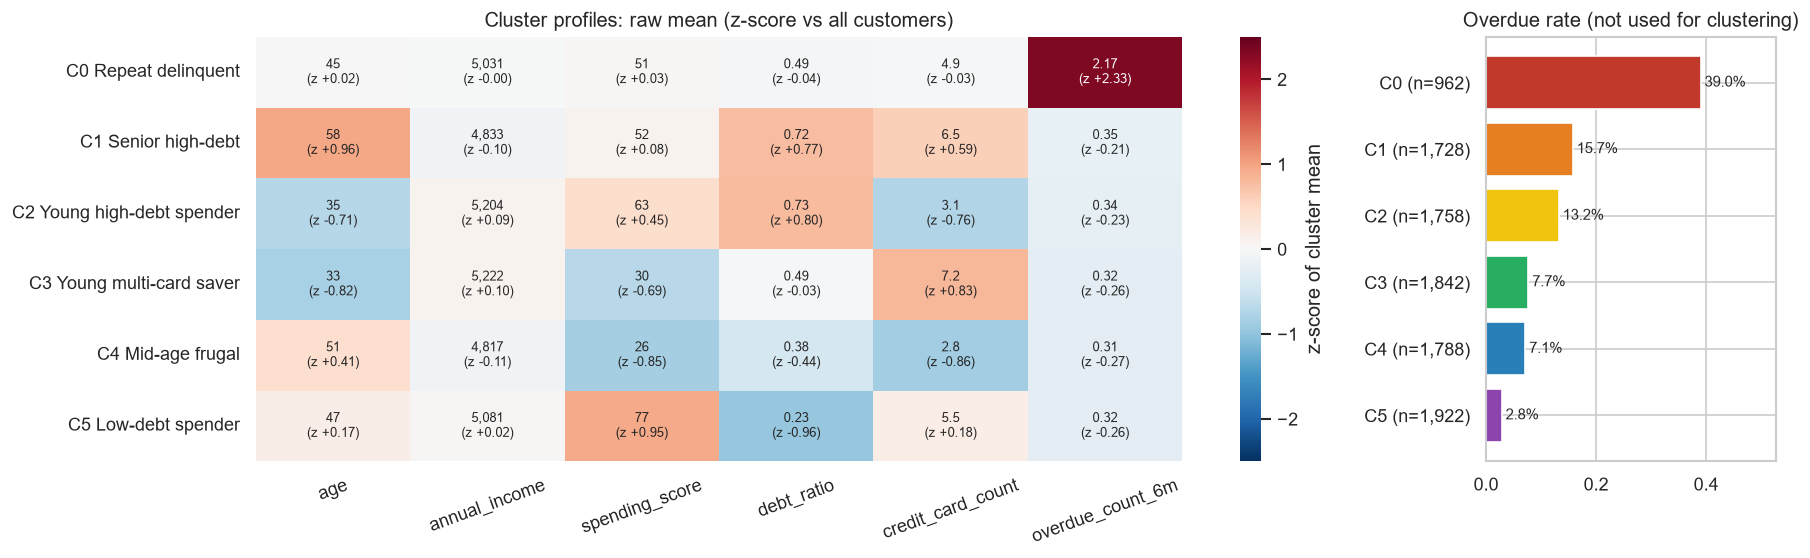

In [7]:
rows = []
for p, n in zip(result["profiles"], result["personas"]):
    rows.append({"cluster": f"C{p['cluster']}", "persona": n["ko"], "size": p["size"], "share": p["share"],
                 **{f: p["mean"][f] for f in FEATURES}, "overdue_rate": p["overdue_rate"],
                 "credit_score": p["credit_score_mean"]})
display(pd.DataFrame(rows).set_index("cluster"))
display(Image(FIGURES_DIR / "03_cluster_profiles.png"))

In [8]:
for n in result["personas"]:
    display(Markdown(f"**C{n['cluster']} {n['ko']}** — {n['summary']}  \n대상: {n['target']} · 메시지: {n['message']} · 액션: {n['action']}"))

**C0 연체 반복형** — 최근 6개월 연체가 모두 2회 이상이다. 다른 변수는 전체 평균과 비슷하다.  
대상: 기존 고객 리스크 관리 · 메시지: 상환 일정을 함께 조정해 연체를 끊는다 · 액션: 신규 한도 동결, 채무 조정 상담, 자동이체 전환 유도. 마케팅 발송 대상에서 제외

**C1 고령·고부채 다카드형** — 나이가 많고 부채 비율과 카드 수가 높다. 연체 이력은 적지만 부채 부담이 크다.  
대상: 보류 심사 집중 대상 · 메시지: 흩어진 카드 부채를 하나로 모아 이자 부담을 줄인다 · 액션: 카드·부채 통합 대환 제안, 부채 비율 변화 모니터링, 신규 카드 발급 억제

**C2 청년·고부채 소비형** — 젊고 부채 비율이 높다. 카드는 적지만 소비 점수가 평균보다 높다.  
대상: 성장 잠재 고객, 단계적 관리 · 메시지: 쓰는 만큼 관리하면 한도가 함께 커진다 · 액션: 소액 한도로 시작해 상환 이력에 따라 단계적 상향, 소비 알림·예산 관리 기능 안내

**C3 청년·다카드 절약형** — 젊고 카드는 많지만 소비 점수가 낮다. 부채 비율은 평균 수준이다.  
대상: 주거래 전환 마케팅 · 메시지: 여러 카드의 혜택을 한 장으로 모은다 · 액션: 주거래 카드 통합 혜택, 적금 연계 상품, 사용하지 않는 카드 정리 안내

**C4 중장년·저소비 실속형** — 소비 점수와 카드 수가 낮고, 부채 비율도 평균보다 조금 낮다.  
대상: 예금·연금 교차 판매 · 메시지: 모아 둔 자산을 안정적으로 불린다 · 액션: 예금·연금·저위험 투자 상품 제안, 간소화 심사로 대출 절차 단축

**C5 저부채 고소비 우량형** — 부채 비율이 가장 낮고 소비 점수가 가장 높다.  
대상: VIP 육성 · 메시지: 많이 쓰는 만큼 더 돌려받는다 · 액션: 프리미엄 카드, 한도 상향 사전 승인, 소비 리워드 강화

## 6. 보너스 2 — 군집화 알고리즘 비교

같은 2,000명 표본에서 K-Means, 계층적 군집(ward·complete·average), DBSCAN을 비교한다. 계층적 군집은 거리 행렬이 고객 수의 제곱으로 커지므로 표본에서만 돌린다.

,clusters,silhouette,ari_vs_kmeans,sizes,noise_share
method,,,,,
K-Means,6,0.1348,1.0000,"[184, 320, 357, 390, 379, 370]",0.0000
Hierarchical (ward),6,0.0628,0.1914,"[457, 426, 361, 287, 260, 209]",0.0000
Hierarchical (complete),6,0.0432,0.1061,"[594, 443, 373, 296, 157, 137]",0.0000
Hierarchical (average),6,0.0160,0.0355,"[1807, 99, 81, 7, 4, 2]",0.0000
DBSCAN,3,0.0951,0.0683,"[2943, 6056, 648]",0.0353


DBSCAN eps=1.133(k-거리 곡선의 꺾이는 점), min_samples=12


,0,1,2,3,4
DBSCAN label,,,,,
-1,13,25,165,134,16
0,0,2943,0,0,0
1,6056,0,0,0,0
2,0,0,648,0,0


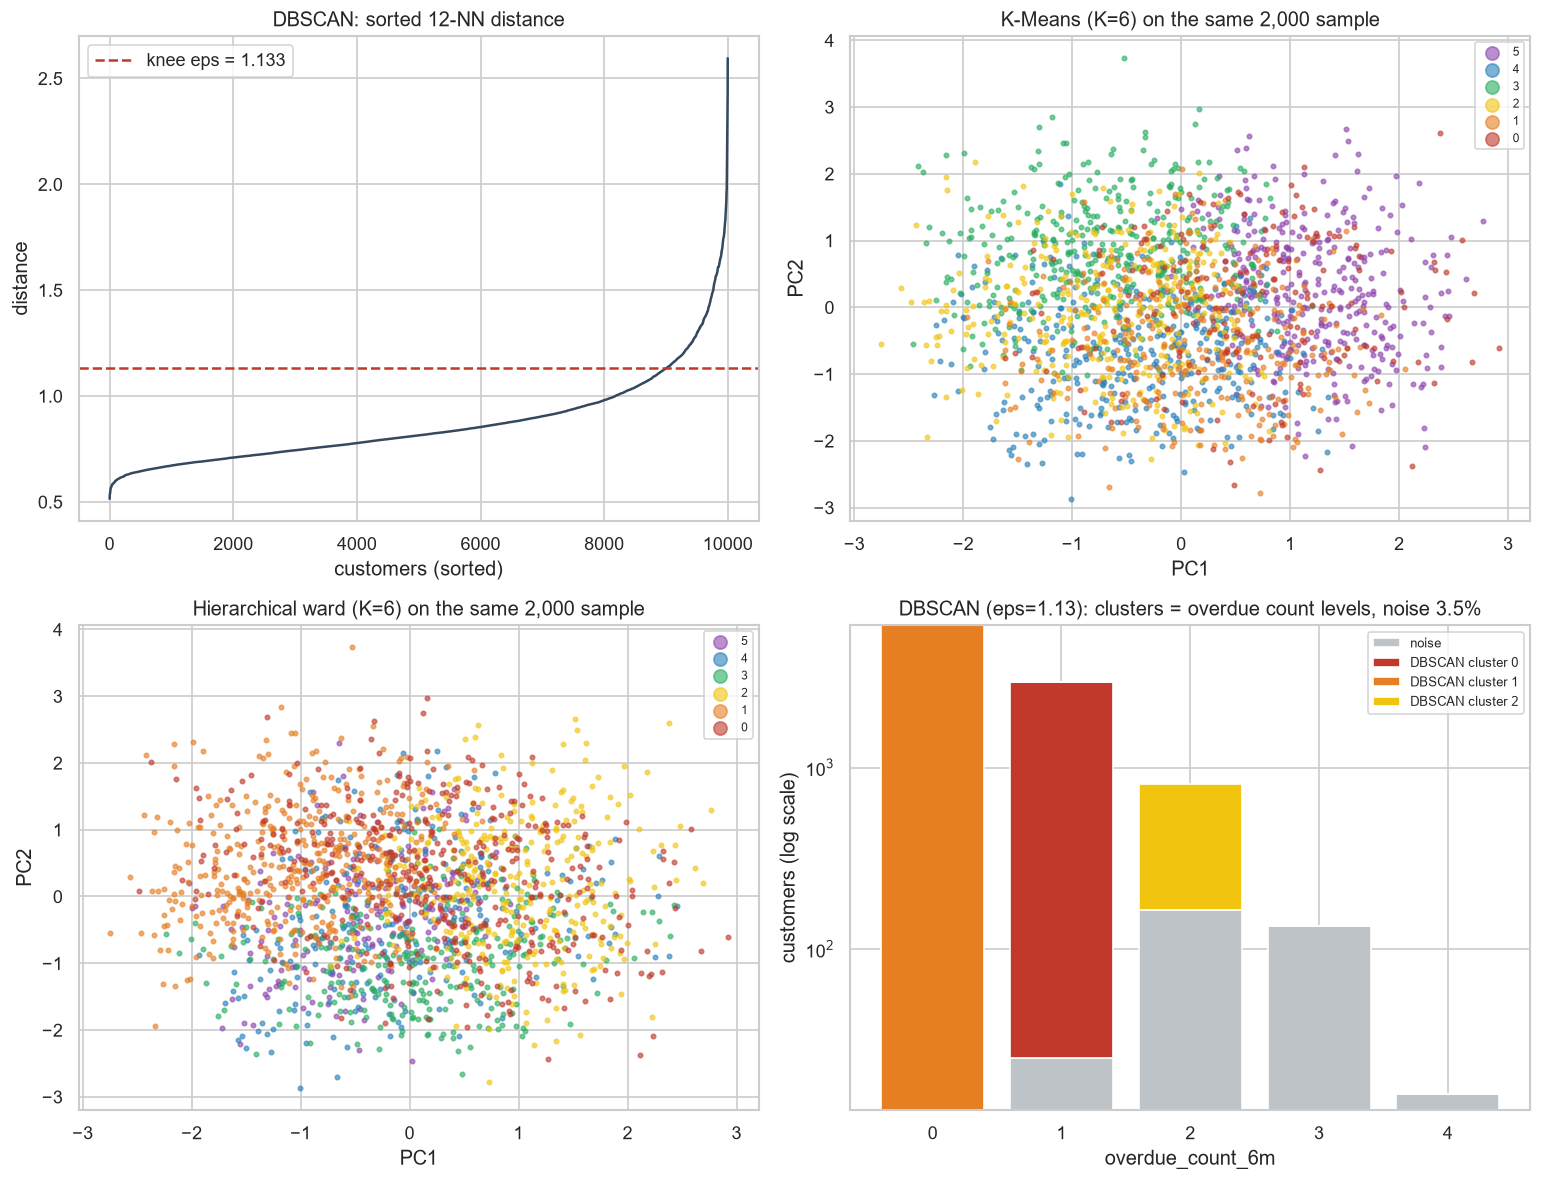

In [9]:
cmp = result["comparison"]
display(pd.DataFrame(cmp["table"]).set_index("method"))
db = cmp["dbscan"]
print(f"DBSCAN eps={db['eps']:.3f}(k-거리 곡선의 꺾이는 점), min_samples={db['min_samples']}")
display(pd.DataFrame(db["overdue_count_crosstab"]).T.rename_axis("DBSCAN label"))
display(Image(FIGURES_DIR / "13_clustering_comparison.png"))

- 알고리즘끼리 일치도(ARI)가 0.04~0.19로 낮다. 진짜 군집이 있다면 방법이 달라도 비슷한 답이 나온다. 결과가 이렇게 엇갈리는 것 자체가 "자연스러운 군집이 없다"는 증거다.
- DBSCAN은 연체 횟수 0·1·2회를 각각 하나의 군집으로 나누고, 3회 이상은 노이즈로 분류한다. 이산 변수의 값 사이 빈틈이 이 데이터에서 유일하게 밀도가 끊기는 곳이기 때문이다. 밀도 기반 방법은 데이터에 실제로 있는 빈틈만 찾는다.
- average 연결은 한 군집에 1,807명이 몰린다. 평균 거리 기준은 경계가 흐린 데이터에서 큰 덩어리 하나와 소수의 외톨이로 나뉘기 쉽다.